# 🛰️ Satellite Imagery Crop Type Classification: ML for Agricultural Statistics

**Author:** Dean Wang | Lead Data & AI Engineer

**Government:** ABARES, ABS (agricultural census), Geoscience Australia (Digital Earth Australia), DAFF

Dataset: sklearn synthetic — NO dataset needed.

---

Generated: (2500, 13)


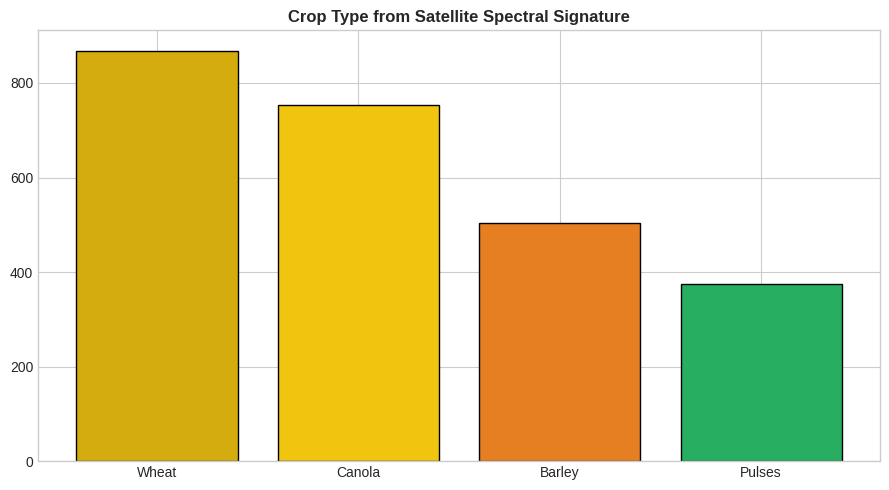

AU: Digital Earth Australia processes 30+ years of Landsat/Sentinel. ABARES uses EO for crop area estimates.


In [1]:
import warnings,time,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,classification_report,cohen_kappa_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings('ignore');plt.style.use('seaborn-v0_8-whitegrid')
X_arr,y=make_classification(n_samples=2500,n_features=12,n_informative=9,n_classes=4,n_clusters_per_class=1,weights=[0.35,0.3,0.2,0.15],random_state=199)
names=['ndvi_peak','ndvi_timing_doy','evi_mean','ndwi_mean','red_edge_ratio','swir_reflectance','phenology_amplitude','greenup_rate','senescence_rate','soil_brightness','rainfall_season','field_size_ha']
df=pd.DataFrame(X_arr,columns=names);df['crop_type']=y;tc='crop_type'
tl=['Wheat','Canola','Barley','Pulses'];nc=4
print(f"Generated: {df.shape}");colors=['#d4ac0d','#f1c40f','#e67e22','#27ae60']
fig,ax=plt.subplots(figsize=(9,5));vc=df[tc].value_counts().sort_index()
ax.bar(range(nc),vc.values,color=colors,edgecolor='black');ax.set_xticks(range(nc));ax.set_xticklabels(tl)
ax.set_title('Crop Type from Satellite Spectral Signature',fontweight='bold');plt.tight_layout();plt.savefig('t.png',dpi=150);plt.show()
print("AU: Digital Earth Australia processes 30+ years of Landsat/Sentinel. ABARES uses EO for crop area estimates.")

LogReg: Acc=0.7824 F1=0.7814 Kappa=0.6978
RF: Acc=0.8924 F1=0.8917 Kappa=0.8509
XGB: Acc=0.8996 F1=0.8993 Kappa=0.8612
LGBM: Acc=0.9012 F1=0.9008 Kappa=0.8633
Best: LGBM


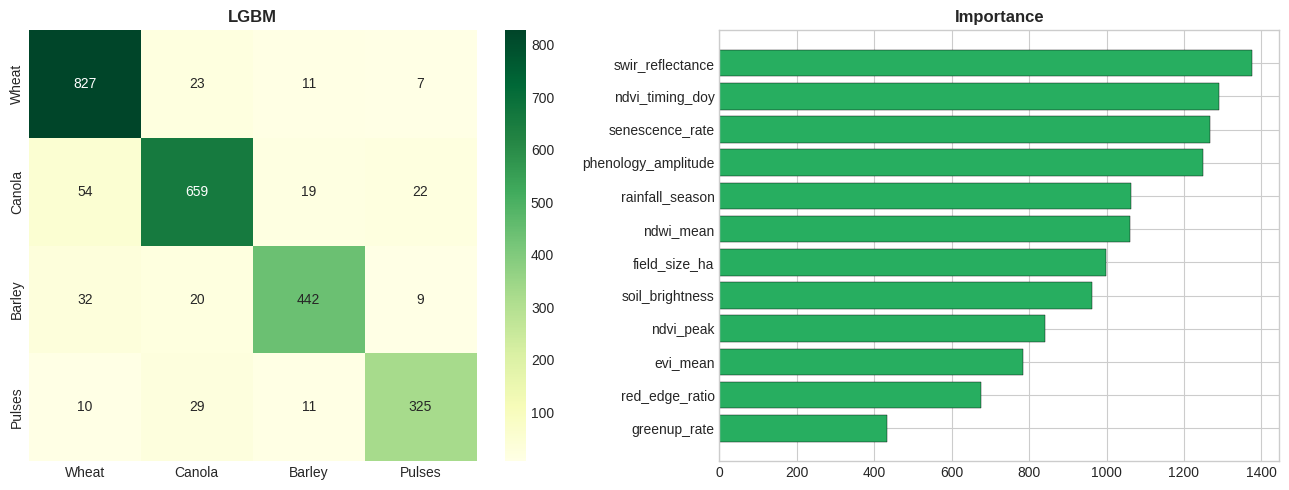

              precision    recall  f1-score   support

       Wheat       0.90      0.95      0.92       868
      Canola       0.90      0.87      0.89       754
      Barley       0.92      0.88      0.90       503
      Pulses       0.90      0.87      0.88       375

    accuracy                           0.90      2500
   macro avg       0.90      0.89      0.90      2500
weighted avg       0.90      0.90      0.90      2500

DEPLOYMENT: LGBM F1=0.9008 Kappa=0.8633 | Sentinel-2 time series -> national crop area statistics


In [2]:
nums=[c2 for c2 in df.columns if c2!=tc];X=df[nums];y2=df[tc].values
try:
    from xgboost import XGBClassifier
except: XGBClassifier=None
try:
    from lightgbm import LGBMClassifier
except: LGBMClassifier=None
models={'LogReg':LogisticRegression(max_iter=2000,random_state=42,multi_class='multinomial'),'RF':RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)}
if XGBClassifier: models['XGB']=XGBClassifier(n_estimators=100,random_state=42,eval_metric='mlogloss',use_label_encoder=False,verbosity=0,n_jobs=-1)
if LGBMClassifier: models['LGBM']=LGBMClassifier(n_estimators=100,random_state=42,verbose=-1,n_jobs=-1,force_col_wise=True)
skf=StratifiedKFold(3,shuffle=True,random_state=42);Xa=X.values;results={}
for mn,mod in models.items():
    fa,ff,fk=[],[],[];fp=np.zeros(len(y2),dtype=int)
    for fi,(ti,vi) in enumerate(skf.split(Xa,y2)):
        m2=type(mod)(**mod.get_params());m2.fit(Xa[ti],y2[ti]);yp=m2.predict(Xa[vi]);fp[vi]=yp
        fa.append(accuracy_score(y2[vi],yp));ff.append(f1_score(y2[vi],yp,average='weighted'));fk.append(cohen_kappa_score(y2[vi],yp))
    results[mn]={'acc':np.mean(fa),'f1':np.mean(ff),'kappa':np.mean(fk),'preds':fp}
    print(f"{mn}: Acc={np.mean(fa):.4f} F1={np.mean(ff):.4f} Kappa={np.mean(fk):.4f}")
best=max(results,key=lambda k:results[k]['f1']);print(f"Best: {best}")
bp=results[best]['preds'];cm=confusion_matrix(y2,bp)
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='YlGn',xticklabels=tl,yticklabels=tl,ax=axes[0]);axes[0].set_title(f'{best}',fontweight='bold')
tm={k:v for k,v in models.items() if k!='LogReg'}
if tm:
    bt=max(tm,key=lambda m4:results[m4]['f1']);fm2=type(models[bt])(**models[bt].get_params());fm2.fit(Xa,y2)
    fi=pd.DataFrame({'Feature':X.columns,'Imp':fm2.feature_importances_}).sort_values('Imp')
    axes[1].barh(fi['Feature'],fi['Imp'],color='#27ae60',edgecolor='black',linewidth=0.3);axes[1].set_title('Importance',fontweight='bold')
plt.tight_layout();plt.savefig('r.png',dpi=150);plt.show()
print(classification_report(y2,bp,target_names=tl))
br=results[best];print(f"DEPLOYMENT: {best} F1={br['f1']:.4f} Kappa={br['kappa']:.4f} | Sentinel-2 time series -> national crop area statistics")